<a href="https://colab.research.google.com/github/Arwamo7med-wq/RoboRescue-RL/blob/main/RoboRescueEnv.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [94]:
import numpy as np
import matplotlib.pyplot as plt
import heapq
import json
import urllib.request
import urllib.error
from collections import deque
from matplotlib.colors import ListedColormap

In [95]:
# 1. GENERAL ROBOT ENVIRONMENT

class RoboRescueEnv:
    """
    General 2D Grid Environment for any maze size and reward settings.
    0 = Free cell, 1 = Wall
    """

    def __init__(
        self,
        maze,
        start,
        goal,
        goal_reward=100,
        step_penalty=-1,
        wall_penalty=-20
    ):
        self.maze = np.array(maze, dtype=int)
        self.rows, self.cols = self.maze.shape
        self.start = start
        self.goal = goal

        self.goal_reward = goal_reward
        self.step_penalty = step_penalty
        self.wall_penalty = wall_penalty

        self.position = start
        self.done = False

        self.actions = {
            0: (-1, 0),  # Up
            1: (1, 0),   # Down
            2: (0, -1),  # Left
            3: (0, 1)    # Right
        }

    def reset(self):
        self.position = self.start
        self.done = False
        return self.position

    def step(self, action):
        """
        Returns: (next_state, reward, done, is_mistake)
        is_mistake = True when the robot hits a wall or boundary.
        """
        if self.done:
            raise ValueError("Episode is already finished. Call reset().")

        move = self.actions[action]
        new_row = self.position[0] + move[0]
        new_col = self.position[1] + move[1]

        # Mistake 1: Out of maze boundaries
        if not (0 <= new_row < self.rows and 0 <= new_col < self.cols):
            return self.position, self.wall_penalty, False, True

        # Mistake 2: Hit a wall
        if self.maze[new_row, new_col] == 1:
            return self.position, self.wall_penalty, False, True

        self.position = (new_row, new_col)

        # Goal reached
        if self.position == self.goal:
            self.done = True
            return self.position, self.goal_reward, True, False

        return self.position, self.step_penalty, False, False


In [96]:
# 2. CLASSICAL SEARCH: BFS & A*


def bfs(maze, start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    nodes_explored = 0

    while queue:
        current = queue.popleft()
        nodes_explored += 1

        if current == goal:
            break

        for dr, dc in directions:
            nr, nc = current[0] + dr, current[1] + dc
            neighbor = (nr, nc)

            if (0 <= nr < maze.shape[0] and
                0 <= nc < maze.shape[1] and
                maze[nr, nc] == 0 and
                neighbor not in visited):
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    if goal not in parent:
        return None, nodes_explored

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()

    return path, nodes_explored


def heuristic(position, goal):
    """Manhattan Distance"""
    return abs(position[0] - goal[0]) + abs(position[1] - goal[1])


def astar(maze, start, goal):
    open_list = []
    heapq.heappush(open_list, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed_set = set()
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    nodes_explored = 0

    while open_list:
        _, current = heapq.heappop(open_list)
        if current in closed_set:
            continue

        closed_set.add(current)
        nodes_explored += 1

        if current == goal:
            break

        for dr, dc in directions:
            nr, nc = current[0] + dr, current[1] + dc
            neighbor = (nr, nc)

            if not (0 <= nr < maze.shape[0] and 0 <= nc < maze.shape[1]):
                continue
            if maze[nr, nc] == 1 or neighbor in closed_set:
                continue

            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(neighbor, float("inf")):
                g_score[neighbor] = tentative_g
                parent[neighbor] = current
                f = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_list, (f, neighbor))

    if goal not in parent:
        return None, nodes_explored

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()

    return path, nodes_explored




In [97]:

# 3. GENERAL Q-LEARNING & RE-LEARNING


def evaluate_policy(env, q_table, max_steps=None):
    """
    Tests what the agent has learned so far WITHOUT exploration (greedy).
    Returns: (path, reached_goal, mistakes_count, steps_taken)
    """
    if max_steps is None:
        max_steps = env.rows * env.cols * 2

    state = env.reset()
    path = [state]
    visited_state_actions = set()
    mistakes = 0
    steps = 0

    for _ in range(max_steps):
        r, c = state
        max_q = np.max(q_table[r, c])
        best_actions = np.where(q_table[r, c] == max_q)[0]
        action = int(np.random.choice(best_actions))

        if (state, action) in visited_state_actions:
            return path, False, mistakes, steps

        visited_state_actions.add((state, action))
        next_state, _, done, is_mistake = env.step(action)
        steps += 1

        if is_mistake:
            mistakes += 1
        else:
            path.append(next_state)

        state = next_state

        if done:
            return path, True, mistakes, steps

    return path, False, mistakes, steps


def q_learning(
    env,
    episodes=1500,
    alpha=0.15,
    gamma=0.95,
    epsilon_start=1.0,
    min_epsilon=0.01,
    max_steps=None,
    checkpoints=None,
    initial_q_table=None
):
    """
    General Q-Learning trainer.
    Supports training from scratch OR transfer/re-learning using initial_q_table.
    """
    if max_steps is None:
        max_steps = env.rows * env.cols * 4

    epsilon_decay = (min_epsilon / epsilon_start) ** (1.0 / (0.8 * episodes))
    epsilon = epsilon_start

    if checkpoints is None:
        checkpoints = [
            max(1, int(episodes * 0.02)),
            max(1, int(episodes * 0.25)),
            episodes
        ]

    num_actions = len(env.actions)
    if initial_q_table is not None:
        q_table = initial_q_table.copy()
    else:
        q_table = np.zeros((env.rows, env.cols, num_actions))

    history = {
        "rewards": [],
        "mistakes": [],
        "steps": [],
        "success": [],
        "epsilon": []
    }
    snapshots = {}

    for ep in range(1, episodes + 1):
        state = env.reset()
        total_reward = 0
        ep_mistakes = 0
        ep_steps = 0
        reached_goal = False

        for _ in range(max_steps):
            r, c = state

            if np.random.random() < epsilon:
                action = np.random.randint(num_actions)
            else:
                max_q = np.max(q_table[r, c])
                best_actions = np.where(q_table[r, c] == max_q)[0]
                action = int(np.random.choice(best_actions))

            next_state, reward, done, is_mistake = env.step(action)
            nr, nc = next_state

            best_next_q = 0.0 if done else np.max(q_table[nr, nc])
            td_target = reward + gamma * best_next_q
            q_table[r, c, action] += alpha * (td_target - q_table[r, c, action])

            state = next_state
            total_reward += reward
            ep_steps += 1
            if is_mistake:
                ep_mistakes += 1

            if done:
                reached_goal = True
                break

        history["rewards"].append(total_reward)
        history["mistakes"].append(ep_mistakes)
        history["steps"].append(ep_steps)
        history["success"].append(1 if reached_goal else 0)
        history["epsilon"].append(epsilon)

        if ep in checkpoints:
            eval_path, eval_done, eval_mistakes, eval_steps = evaluate_policy(env, q_table)
            snapshots[ep] = {
                "path": eval_path,
                "reached_goal": eval_done,
                "mistakes": eval_mistakes,
                "steps": eval_steps
            }

        epsilon = max(min_epsilon, epsilon * epsilon_decay)

    final_path, final_done, _, _ = evaluate_policy(env, q_table)
    final_path = final_path if final_done else None

    return final_path, q_table, history, snapshots


def pick_valid_obstacle(maze, path, start, goal):
    """
    Automatically picks a cell near the middle of the learned path
    that blocks the current path while keeping at least one alternative route open.
    """
    if not path or len(path) < 3:
        return None

    mid = len(path) // 2
    candidates = sorted(
        [p for p in path if p != start and p != goal],
        key=lambda p: abs(path.index(p) - mid)
    )

    for cell in candidates:
        temp_maze = maze.copy()
        temp_maze[cell] = 1
        alt_path, _ = bfs(temp_maze, start, goal)
        if alt_path is not None:
            return cell

    return None

In [98]:

# 4. LEARNING REPORT & VISUALIZATIONS


def print_learning_stages_report(history, title="LEARNING PROGRESS BY STAGE", num_stages=4):
    episodes = len(history["rewards"])
    stage_size = max(1, episodes // num_stages)

    print(f"\n========== {title} ==========")
    print(f"{'Stage (Episodes)':<20} | {'Avg Mistakes':<13} | {'Avg Steps':<10} | {'Success Rate':<13} | {'Avg Reward':<10}")
    print("-" * 78)

    for i in range(num_stages):
        start_idx = i * stage_size
        end_idx = (i + 1) * stage_size if i < num_stages - 1 else episodes
        if start_idx >= episodes:
            break

        avg_mistakes = np.mean(history["mistakes"][start_idx:end_idx])
        avg_steps = np.mean(history["steps"][start_idx:end_idx])
        success_rate = np.mean(history["success"][start_idx:end_idx]) * 100
        avg_reward = np.mean(history["rewards"][start_idx:end_idx])

        label = f"Ep {start_idx + 1} - {end_idx}"
        print(f"{label:<20} | {avg_mistakes:<13.2f} | {avg_steps:<10.2f} | {success_rate:<12.1f}% | {avg_reward:<10.2f}")


def _moving_avg(data, window=50):
    if len(data) < window:
        return np.array(data), np.arange(len(data))
    avg = np.convolve(data, np.ones(window) / window, mode="valid")
    x = np.arange(window - 1, len(data))
    return avg, x


def plot_learning_dashboard(history, window=50):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle("Phase 1: Learning From Mistakes Over Time", fontsize=14, fontweight="bold")

    ax = axes[0, 0]
    ax.plot(history["mistakes"], alpha=0.25, color="salmon", label="Per Episode")
    avg, x = _moving_avg(history["mistakes"], window)
    ax.plot(x, avg, color="darkred", linewidth=2, label=f"Trend ({window}-ep avg)")
    ax.set_title("1. Mistakes (Wall/Boundary Hits) Drop Over Time")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Mistakes Count")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[0, 1]
    ax.plot(history["rewards"], alpha=0.25, color="skyblue", label="Per Episode")
    avg, x = _moving_avg(history["rewards"], window)
    ax.plot(x, avg, color="navy", linewidth=2, label=f"Trend ({window}-ep avg)")
    ax.set_title("2. Total Reward Improves Over Time")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Total Reward")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[1, 0]
    ax.plot(history["steps"], alpha=0.25, color="plum", label="Per Episode")
    avg, x = _moving_avg(history["steps"], window)
    ax.plot(x, avg, color="purple", linewidth=2, label=f"Trend ({window}-ep avg)")
    ax.set_title("3. Steps to Goal Become Shorter & Faster")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Steps")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[1, 1]
    avg_success, x = _moving_avg(np.array(history["success"]) * 100, window)
    ax.plot(x, avg_success, color="green", linewidth=2.5, label=f"Success Rate ({window}-ep avg)")
    ax.set_ylim(-5, 105)
    ax.set_title("4. Success Rate Climbs Toward 100%")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Success Rate (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def draw_learning_stages(maze, start, goal, snapshots):
    cols = len(snapshots)
    fig, axes = plt.subplots(1, cols, figsize=(5 * cols, 5))
    if cols == 1:
        axes = [axes]

    colors = ["white", "black", "orange", "blue", "green", "red"]
    cmap = ListedColormap(colors)

    for ax, (ep, info) in zip(axes, snapshots.items()):
        visual_maze = maze.copy()
        for pos in info["path"]:
            if pos != start and pos != goal:
                visual_maze[pos] = 2
        visual_maze[start] = 3
        visual_maze[goal] = 4

        status = "Reached Goal" if info["reached_goal"] else "Got Stuck / Failed"
        ax.imshow(visual_maze, cmap=cmap, vmin=0, vmax=5)
        ax.set_title(
            f"After Episode {ep}\n"
            f"{status} | Steps: {info['steps']} | Mistakes: {info['mistakes']}"
        )
        ax.set_xticks(range(maze.shape[1]))
        ax.set_yticks(range(maze.shape[0]))
        ax.grid(True)

    fig.suptitle("Phase 1: How the Robot's Path Evolves Through Experience", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_adaptation_timeline(history1, history2, window=30):
    """
    Combines Phase 1 (Initial Learning) and Phase 2 (Re-learning after Sudden Wall)
    into one continuous timeline to show shock and recovery.
    """
    change_point = len(history1["mistakes"])
    all_mistakes = history1["mistakes"] + history2["mistakes"]
    all_rewards = history1["rewards"] + history2["rewards"]
    all_success = (history1["success"] + history2["success"])

    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    fig.suptitle("Dynamic Adaptation: Shock & Re-Learning When a Sudden Wall Appears",
                 fontsize=14, fontweight="bold")

    # 1. Mistakes Timeline
    ax = axes[0]
    ax.plot(all_mistakes, alpha=0.25, color="salmon")
    avg, x = _moving_avg(all_mistakes, window)
    ax.plot(x, avg, color="darkred", linewidth=2, label="Mistakes Trend")
    ax.axvline(change_point, color="red", linestyle="--", linewidth=2, label="New Wall Appears!")
    ax.set_ylabel("Mistakes")
    ax.set_title("Mistakes Spike Briefly at Change Point, Then Drop Back to 0")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 2. Reward Timeline
    ax = axes[1]
    ax.plot(all_rewards, alpha=0.25, color="skyblue")
    avg, x = _moving_avg(all_rewards, window)
    ax.plot(x, avg, color="navy", linewidth=2, label="Reward Trend")
    ax.axvline(change_point, color="red", linestyle="--", linewidth=2, label="New Wall Appears!")
    ax.set_ylabel("Total Reward")
    ax.set_title("Reward Recovers Quickly Using Prior Knowledge")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 3. Success Rate Timeline
    ax = axes[2]
    avg_s, x = _moving_avg(np.array(all_success) * 100, window)
    ax.plot(x, avg_s, color="green", linewidth=2.5, label="Success Rate (%)")
    ax.axvline(change_point, color="red", linestyle="--", linewidth=2, label="New Wall Appears!")
    ax.set_ylim(-5, 105)
    ax.set_xlabel("Total Cumulative Episodes")
    ax.set_ylabel("Success Rate (%)")
    ax.set_title("Success Rate Recovers Back to ~100% on the New Maze")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def draw_adaptation_comparison(
    original_maze, new_maze, start, goal, new_wall,
    old_path, shock_info, adapted_path
):
    """
    3-panel comparison:
    1. Original learned path
    2. Moment new red wall appears (old policy fails)
    3. New adapted path around the red wall after re-learning
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    colors = ["white", "black", "orange", "blue", "green", "red"]
    cmap = ListedColormap(colors)

    panels = [
        (
            original_maze,
            old_path,
            f"1. Original Path\nSteps: {len(old_path) - 1} | Mistakes: 0",
            False
        ),
        (
            new_maze,
            shock_info["path"],
            f"2. Sudden Wall {new_wall} Appears\n"
            f"{'Reached' if shock_info['reached_goal'] else 'Blocked / Failed'} | Mistakes: {shock_info['mistakes']}",
            True
        ),
        (
            new_maze,
            adapted_path if adapted_path else [],
            f"3. Adapted Path After Re-Learning\n"
            f"{f'Steps: {len(adapted_path) - 1} | Mistakes: 0' if adapted_path else 'Failed'}",
            True
        )
    ]

    for ax, (m, p, title, highlight_wall) in zip(axes, panels):
        visual = m.copy()
        if p:
            for pos in p:
                if pos != start and pos != goal:
                    visual[pos] = 2
        if highlight_wall:
            visual[new_wall] = 5  # Highlight sudden obstacle in RED
        visual[start] = 3
        visual[goal] = 4

        ax.imshow(visual, cmap=cmap, vmin=0, vmax=5)
        ax.set_title(title)
        ax.set_xticks(range(m.shape[1]))
        ax.set_yticks(range(m.shape[0]))
        ax.grid(True)

    fig.suptitle("How the Robot Adapts to a Sudden Obstacle (Red = New Wall)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

In [99]:

# ==========================================
# 5. ESP32 COMMUNICATION
# ==========================================

def path_to_commands(path):
    if not path or len(path) < 2:
        return ""

    direction_map = {(-1, 0): "U", (1, 0): "D", (0, -1): "L", (0, 1): "R"}
    commands = []
    for i in range(len(path) - 1):
        dr = path[i + 1][0] - path[i][0]
        dc = path[i + 1][1] - path[i][1]
        commands.append(direction_map[(dr, dc)])
    return "".join(commands)


def send_to_esp32_wifi(commands_str, esp32_ip="192.168.1.100", port=80):
    url = f"http://{esp32_ip}:{port}/move"
    payload = json.dumps({"commands": commands_str}).encode("utf-8")
    req = urllib.request.Request(
        url, data=payload,
        headers={"Content-Type": "application/json"},
        method="POST"
    )
    try:
        with urllib.request.urlopen(req, timeout=5) as response:
            print(f"[ESP32 WiFi] Sent '{commands_str}' | Response: {response.read().decode('utf-8')}")
    except urllib.error.URLError as e:
        print(f"[ESP32 WiFi] Connection failed: {e}")


def send_to_esp32_serial(commands_str, port="COM3", baudrate=115200):
    try:
        import serial
        import time
    except ImportError:
        print("[ESP32 Serial] Install pyserial first: pip install pyserial")
        return

    try:
        with serial.Serial(port, baudrate, timeout=2) as ser:
            time.sleep(2)
            ser.write((commands_str + "\n").encode("utf-8"))
            reply = ser.readline().decode("utf-8").strip()
            print(f"[ESP32 Serial] Sent '{commands_str}' | Response: {reply}")
    except Exception as e:
        print(f"[ESP32 Serial] Connection failed: {e}")

In [100]:

# ==========================================
# 6. GENERAL EXPERIMENT PIPELINE
# ==========================================
def run_maze_experiment(
    maze,
    start,
    goal,
    episodes=1500,
    test_dynamic_obstacle=True,
    new_wall=None,
    relearn_episodes=600,
    esp32_mode="NONE",
    esp32_ip="192.168.1.100",
    serial_port="COM3"
):
    maze = np.array(maze, dtype=int)

    # ---------- PHASE 1: INITIAL TRAINING ----------
    bfs_path, bfs_nodes = bfs(maze, start, goal)
    astar_path, astar_nodes = astar(maze, start, goal)

    env = RoboRescueEnv(maze, start, goal)
    ql_path, q_table, history, snapshots = q_learning(env, episodes=episodes)

    print_learning_stages_report(history, title="PHASE 1: INITIAL LEARNING PROGRESS", num_stages=4)

    print("\n========== PHASE 1: ALGORITHM COMPARISON ==========")
    if bfs_path:
        print(f"BFS        -> Steps: {len(bfs_path) - 1} | Nodes Explored: {bfs_nodes}")
    if astar_path:
        print(f"A*         -> Steps: {len(astar_path) - 1} | Nodes Explored: {astar_nodes}")
    if ql_path:
        print(f"Q-Learning -> Steps: {len(ql_path) - 1} | Final 100-ep Avg Mistakes: {np.mean(history['mistakes'][-100:]):.2f}")
    else:
        print("Q-Learning -> Could not find a valid path.")

    draw_learning_stages(maze, start, goal, snapshots)
    plot_learning_dashboard(history, window=max(10, episodes // 30))

    final_valid_path = ql_path if ql_path else astar_path

    # ---------- PHASE 2: SUDDEN OBSTACLE & RE-LEARNING ----------
    if test_dynamic_obstacle and ql_path:
        wall_pos = new_wall if new_wall is not None else pick_valid_obstacle(maze, ql_path, start, goal)

        if wall_pos is None:
            print("\n[Dynamic Test Skipped] No alternate route exists if any path cell is blocked.")
        else:
            print(f"\n========== PHASE 2: SUDDEN OBSTACLE AT {wall_pos} ==========")
            new_maze = maze.copy()
            new_maze[wall_pos] = 1
            new_env = RoboRescueEnv(new_maze, start, goal)

            # Evaluate old policy immediately when obstacle appears (before re-learning)
            shock_path, shock_done, shock_mistakes, shock_steps = evaluate_policy(new_env, q_table)
            shock_info = {
                "path": shock_path,
                "reached_goal": shock_done,
                "mistakes": shock_mistakes,
                "steps": shock_steps
            }
            print(f"Before Re-Learning -> Reached Goal: {shock_done} | Mistakes: {shock_mistakes}")

            # Re-learn using previous Q-Table with moderate re-exploration (epsilon=0.6)
            adapted_path, adapted_q_table, history2, _ = q_learning(
                new_env,
                episodes=relearn_episodes,
                epsilon_start=0.6,
                initial_q_table=q_table
            )

            print_learning_stages_report(history2, title="PHASE 2: RE-LEARNING PROGRESS", num_stages=3)

            # Compare with A* on the new maze as reference
            new_astar_path, _ = astar(new_maze, start, goal)
            print("\n========== PHASE 2: ADAPTATION RESULT ==========")
            if new_astar_path:
                print(f"A* Optimal on New Maze      -> Steps: {len(new_astar_path) - 1}")
            if adapted_path:
                print(f"Adapted Q-Learning Path     -> Steps: {len(adapted_path) - 1} | Final 100-ep Avg Mistakes: {np.mean(history2['mistakes'][-100:]):.2f}")
                final_valid_path = adapted_path
            else:
                print("Adapted Q-Learning -> Could not adapt within the given episodes.")

            draw_adaptation_comparison(
                maze, new_maze, start, goal, wall_pos,
                ql_path, shock_info, adapted_path
            )
            plot_adaptation_timeline(history, history2, window=max(10, relearn_episodes // 20))

    # ---------- PHASE 3: SEND FINAL PATH TO ESP32 ----------
    commands_str = path_to_commands(final_valid_path)
    print("\n========== ESP32 COMMANDS ==========")
    print("Generated Commands:", commands_str)

    if commands_str:
        if esp32_mode == "WIFI":
            send_to_esp32_wifi(commands_str, esp32_ip=esp32_ip)
        elif esp32_mode == "SERIAL":
            send_to_esp32_serial(commands_str, port=serial_port)
        else:
            print("ESP32 sending skipped (esp32_mode='NONE').")


========== PHASE 1: INITIAL LEARNING PROGRESS ==========
Stage (Episodes)     | Avg Mistakes  | Avg Steps  | Success Rate  | Avg Reward
------------------------------------------------------------------------------
Ep 1 - 375           | 17.60         | 54.34      | 94.7        % | -293.13   
Ep 376 - 750         | 0.86          | 16.27      | 100.0       % | 68.41     
Ep 751 - 1125        | 0.18          | 14.46      | 100.0       % | 83.20     
Ep 1126 - 1500       | 0.06          | 14.17      | 100.0       % | 85.72     

========== PHASE 1: ALGORITHM COMPARISON ==========
BFS        -> Steps: 14 | Nodes Explored: 42
A*         -> Steps: 14 | Nodes Explored: 16
Q-Learning -> Steps: 14 | Final 100-ep Avg Mistakes: 0.05


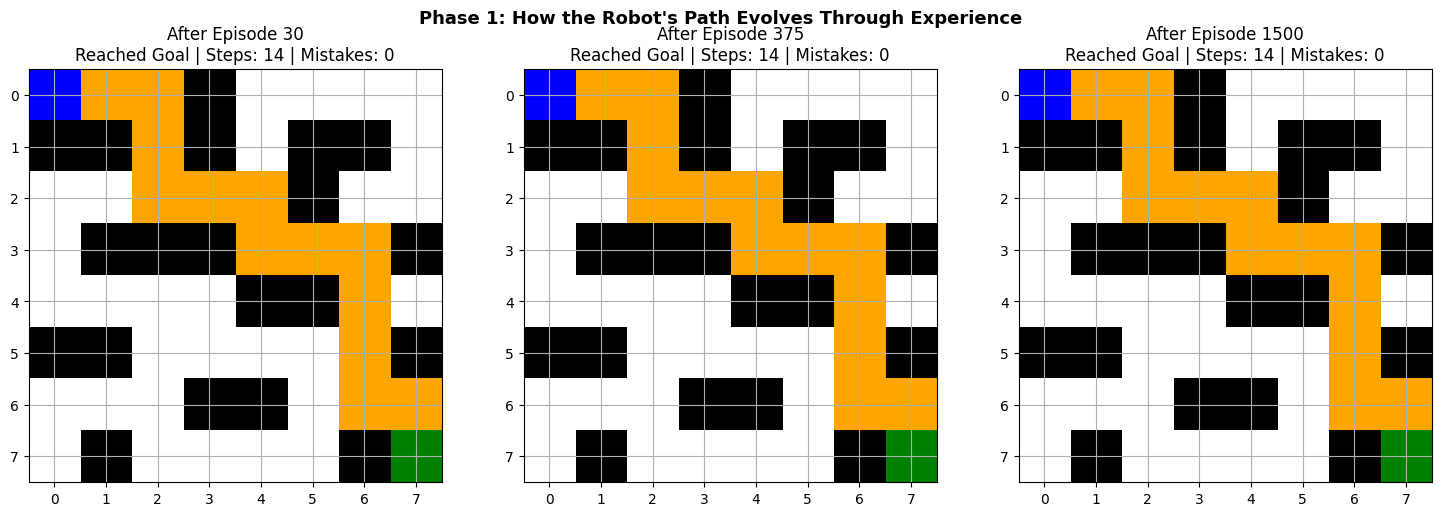

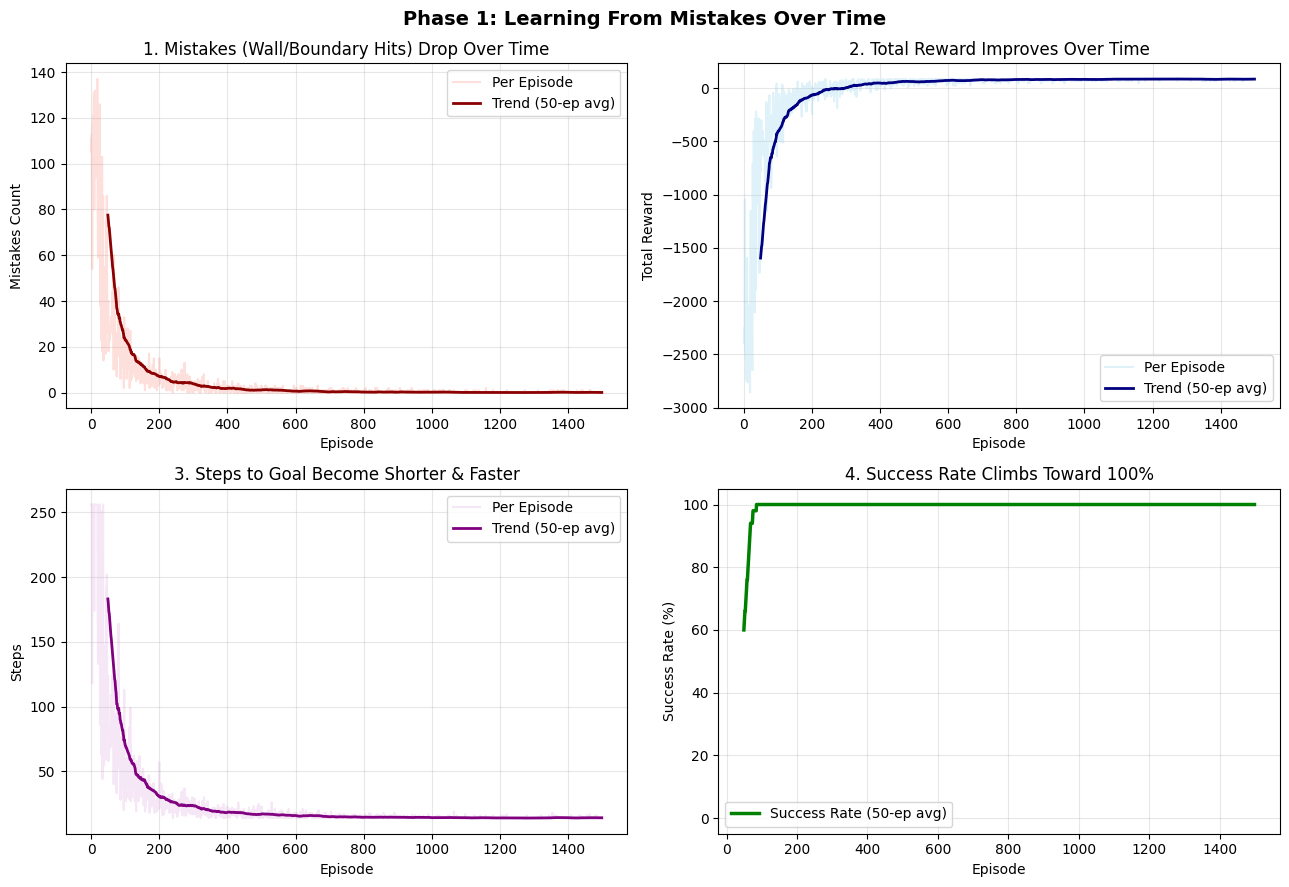


========== PHASE 2: SUDDEN OBSTACLE AT (3, 4) ==========
Before Re-Learning -> Reached Goal: False | Mistakes: 1

========== PHASE 2: RE-LEARNING PROGRESS ==========
Stage (Episodes)     | Avg Mistakes  | Avg Steps  | Success Rate  | Avg Reward
------------------------------------------------------------------------------
Ep 1 - 200           | 8.83          | 46.42      | 95.5        % | -117.74   
Ep 201 - 400         | 0.54          | 21.16      | 100.0       % | 69.58     
Ep 401 - 600         | 0.12          | 20.25      | 100.0       % | 78.57     

========== PHASE 2: ADAPTATION RESULT ==========
A* Optimal on New Maze      -> Steps: 18
Adapted Q-Learning Path     -> Steps: 20 | Final 100-ep Avg Mistakes: 0.12


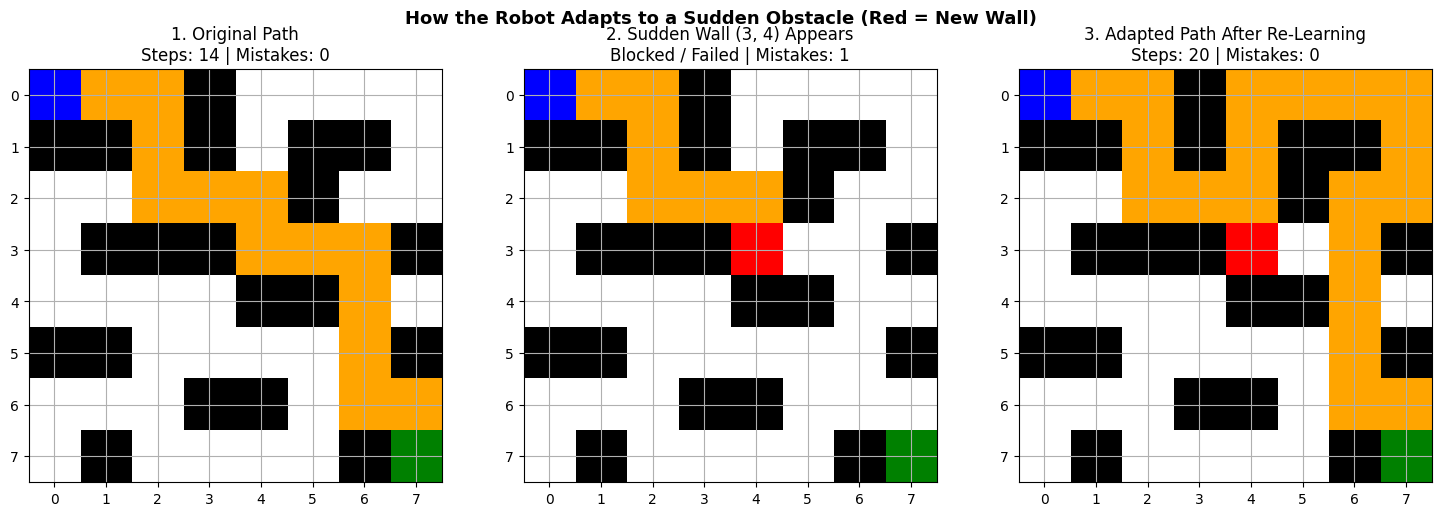

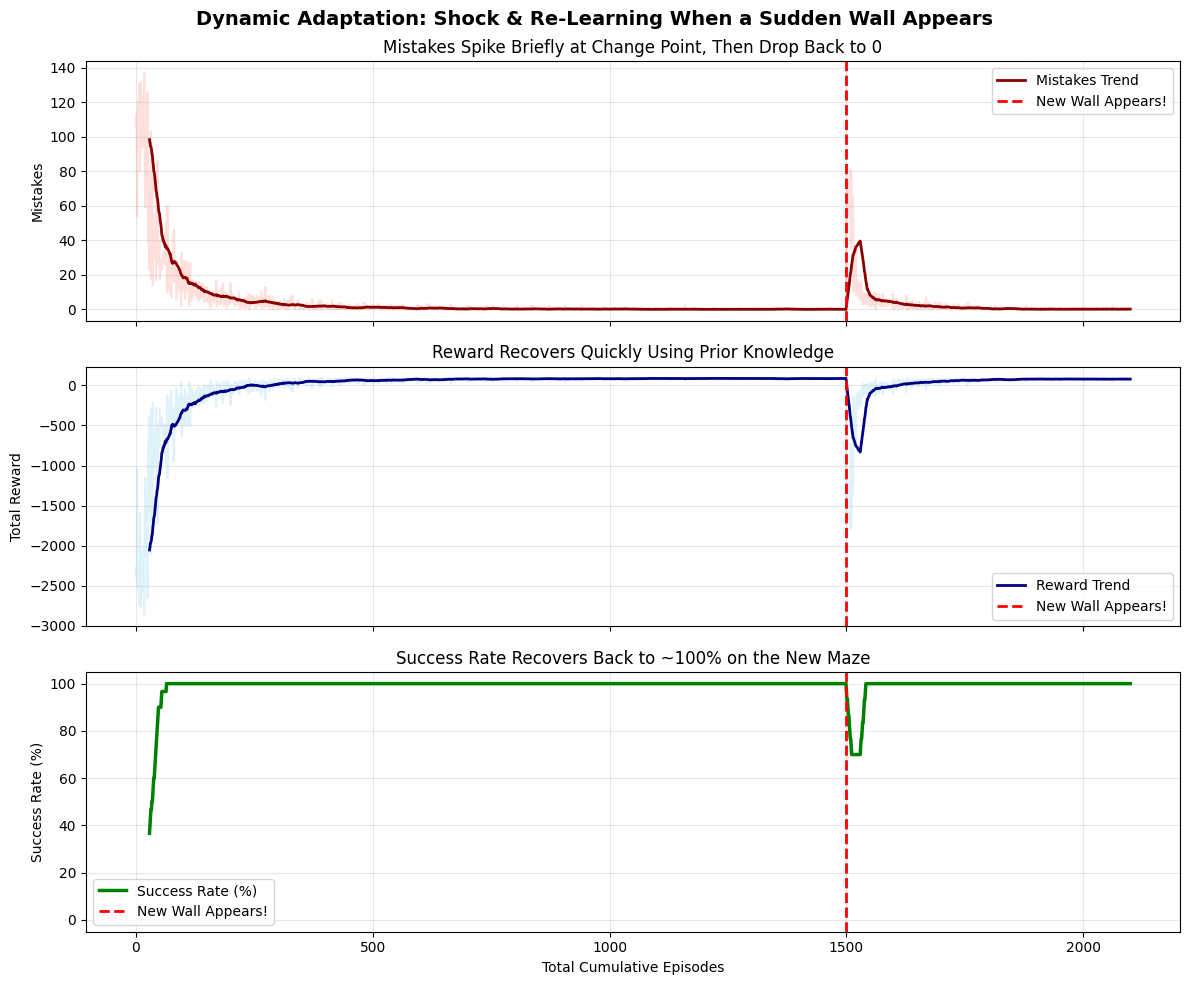


========== ESP32 COMMANDS ==========
Generated Commands: RRDDRRUURRRDDLDDDDRD
ESP32 sending skipped (esp32_mode='NONE').


In [101]:
# 7. RUN EXPERIMENT

maze_8x8 = [
    [0, 0, 0, 1, 0, 0, 0, 0],
    [1, 1, 0, 1, 0, 1, 1, 0],
    [0, 0, 0, 0, 0, 1, 0, 0],
    [0, 1, 1, 1, 0, 0, 0, 1],
    [0, 0, 0, 0, 1, 1, 0, 0],
    [1, 1, 0, 0, 0, 0, 0, 1],
    [0, 0, 0, 1, 1, 0, 0, 0],
    [0, 1, 0, 0, 0, 0, 1, 0]
]

run_maze_experiment(
    maze=maze_8x8,
    start=(0, 0),
    goal=(7, 7),
    episodes=1500,
    test_dynamic_obstacle=True,
    new_wall=None,
    relearn_episodes=600,
    esp32_mode="NONE"
)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import heapq
import json
import urllib.request
import urllib.error
from collections import deque
from matplotlib.colors import ListedColormap


# ==========================================
# 1. GENERAL ROBOT ENVIRONMENT
# ==========================================

class RoboRescueEnv:
    """
    General 2D Grid Environment for any maze size and reward settings.
    0 = Free cell, 1 = Wall
    """

    def __init__(
        self,
        maze,
        start,
        goal,
        goal_reward=100,
        step_penalty=-1,
        wall_penalty=-20
    ):
        self.maze = np.array(maze, dtype=int)
        self.rows, self.cols = self.maze.shape
        self.start = start
        self.goal = goal

        self.goal_reward = goal_reward
        self.step_penalty = step_penalty
        self.wall_penalty = wall_penalty

        self.position = start
        self.done = False

        self.actions = {
            0: (-1, 0),  # Up
            1: (1, 0),   # Down
            2: (0, -1),  # Left
            3: (0, 1)    # Right
        }

    def reset(self):
        self.position = self.start
        self.done = False
        return self.position

    def step(self, action):
        """
        Returns: (next_state, reward, done, is_mistake)
        is_mistake = True when the robot hits a wall or boundary.
        """
        if self.done:
            raise ValueError("Episode is already finished. Call reset().")

        move = self.actions[action]
        new_row = self.position[0] + move[0]
        new_col = self.position[1] + move[1]

        # Mistake 1: Out of maze boundaries
        if not (0 <= new_row < self.rows and 0 <= new_col < self.cols):
            return self.position, self.wall_penalty, False, True

        # Mistake 2: Hit a wall
        if self.maze[new_row, new_col] == 1:
            return self.position, self.wall_penalty, False, True

        self.position = (new_row, new_col)

        # Goal reached
        if self.position == self.goal:
            self.done = True
            return self.position, self.goal_reward, True, False

        return self.position, self.step_penalty, False, False


# ==========================================
# 2. CLASSICAL SEARCH: BFS & A*
# ==========================================

def bfs(maze, start, goal):
    queue = deque([start])
    visited = {start}
    parent = {start: None}
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    nodes_explored = 0

    while queue:
        current = queue.popleft()
        nodes_explored += 1

        if current == goal:
            break

        for dr, dc in directions:
            nr, nc = current[0] + dr, current[1] + dc
            neighbor = (nr, nc)

            if (0 <= nr < maze.shape[0] and
                0 <= nc < maze.shape[1] and
                maze[nr, nc] == 0 and
                neighbor not in visited):
                visited.add(neighbor)
                parent[neighbor] = current
                queue.append(neighbor)

    if goal not in parent:
        return None, nodes_explored

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()

    return path, nodes_explored


def heuristic(position, goal):
    """Manhattan Distance"""
    return abs(position[0] - goal[0]) + abs(position[1] - goal[1])


def astar(maze, start, goal):
    open_list = []
    heapq.heappush(open_list, (heuristic(start, goal), start))

    g_score = {start: 0}
    parent = {start: None}
    closed_set = set()
    directions = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    nodes_explored = 0

    while open_list:
        _, current = heapq.heappop(open_list)
        if current in closed_set:
            continue

        closed_set.add(current)
        nodes_explored += 1

        if current == goal:
            break

        for dr, dc in directions:
            nr, nc = current[0] + dr, current[1] + dc
            neighbor = (nr, nc)

            if not (0 <= nr < maze.shape[0] and 0 <= nc < maze.shape[1]):
                continue
            if maze[nr, nc] == 1 or neighbor in closed_set:
                continue

            tentative_g = g_score[current] + 1
            if tentative_g < g_score.get(neighbor, float("inf")):
                g_score[neighbor] = tentative_g
                parent[neighbor] = current
                f = tentative_g + heuristic(neighbor, goal)
                heapq.heappush(open_list, (f, neighbor))

    if goal not in parent:
        return None, nodes_explored

    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    path.reverse()

    return path, nodes_explored


# ==========================================
# 3. GENERAL Q-LEARNING & RE-LEARNING
# ==========================================

def evaluate_policy(env, q_table, max_steps=None):
    """
    Tests what the agent has learned so far WITHOUT exploration (greedy).
    Returns: (path, reached_goal, mistakes_count, steps_taken)
    """
    if max_steps is None:
        max_steps = env.rows * env.cols * 2

    state = env.reset()
    path = [state]
    visited_state_actions = set()
    mistakes = 0
    steps = 0

    for _ in range(max_steps):
        r, c = state
        max_q = np.max(q_table[r, c])
        best_actions = np.where(q_table[r, c] == max_q)[0]
        action = int(np.random.choice(best_actions))

        if (state, action) in visited_state_actions:
            return path, False, mistakes, steps

        visited_state_actions.add((state, action))
        next_state, _, done, is_mistake = env.step(action)
        steps += 1

        if is_mistake:
            mistakes += 1
        else:
            path.append(next_state)

        state = next_state

        if done:
            return path, True, mistakes, steps

    return path, False, mistakes, steps


def q_learning(
    env,
    episodes=1500,
    alpha=0.15,
    gamma=0.95,
    epsilon_start=1.0,
    min_epsilon=0.01,
    max_steps=None,
    checkpoints=None,
    initial_q_table=None
):
    """
    General Q-Learning trainer.
    Supports training from scratch OR transfer/re-learning using initial_q_table.
    """
    if max_steps is None:
        max_steps = env.rows * env.cols * 4

    epsilon_decay = (min_epsilon / epsilon_start) ** (1.0 / (0.8 * episodes))
    epsilon = epsilon_start

    if checkpoints is None:
        checkpoints = [
            max(1, int(episodes * 0.02)),
            max(1, int(episodes * 0.25)),
            episodes
        ]

    num_actions = len(env.actions)
    if initial_q_table is not None:
        q_table = initial_q_table.copy()
    else:
        q_table = np.zeros((env.rows, env.cols, num_actions))

    history = {
        "rewards": [],
        "mistakes": [],
        "steps": [],
        "success": [],
        "epsilon": []
    }
    snapshots = {}

    for ep in range(1, episodes + 1):
        state = env.reset()
        total_reward = 0
        ep_mistakes = 0
        ep_steps = 0
        reached_goal = False

        for _ in range(max_steps):
            r, c = state

            if np.random.random() < epsilon:
                action = np.random.randint(num_actions)
            else:
                max_q = np.max(q_table[r, c])
                best_actions = np.where(q_table[r, c] == max_q)[0]
                action = int(np.random.choice(best_actions))

            next_state, reward, done, is_mistake = env.step(action)
            nr, nc = next_state

            best_next_q = 0.0 if done else np.max(q_table[nr, nc])
            td_target = reward + gamma * best_next_q
            q_table[r, c, action] += alpha * (td_target - q_table[r, c, action])

            state = next_state
            total_reward += reward
            ep_steps += 1
            if is_mistake:
                ep_mistakes += 1

            if done:
                reached_goal = True
                break

        history["rewards"].append(total_reward)
        history["mistakes"].append(ep_mistakes)
        history["steps"].append(ep_steps)
        history["success"].append(1 if reached_goal else 0)
        history["epsilon"].append(epsilon)

        if ep in checkpoints:
            eval_path, eval_done, eval_mistakes, eval_steps = evaluate_policy(env, q_table)
            snapshots[ep] = {
                "path": eval_path,
                "reached_goal": eval_done,
                "mistakes": eval_mistakes,
                "steps": eval_steps
            }

        epsilon = max(min_epsilon, epsilon * epsilon_decay)

    final_path, final_done, _, _ = evaluate_policy(env, q_table)
    final_path = final_path if final_done else None

    return final_path, q_table, history, snapshots


def pick_valid_obstacle(maze, path, start, goal):
    """
    Automatically picks a cell near the middle of the learned path
    that blocks the current path while keeping at least one alternative route open.
    """
    if not path or len(path) < 3:
        return None

    mid = len(path) // 2
    candidates = sorted(
        [p for p in path if p != start and p != goal],
        key=lambda p: abs(path.index(p) - mid)
    )

    for cell in candidates:
        temp_maze = maze.copy()
        temp_maze[cell] = 1
        alt_path, _ = bfs(temp_maze, start, goal)
        if alt_path is not None:
            return cell

    return None


# ==========================================
# 4. LEARNING REPORT & VISUALIZATIONS
# ==========================================

def print_learning_stages_report(history, title="LEARNING PROGRESS BY STAGE", num_stages=4):
    episodes = len(history["rewards"])
    stage_size = max(1, episodes // num_stages)

    print(f"\n========== {title} ==========")
    print(f"{'Stage (Episodes)':<20} | {'Avg Mistakes':<13} | {'Avg Steps':<10} | {'Success Rate':<13} | {'Avg Reward':<10}")
    print("-" * 78)

    for i in range(num_stages):
        start_idx = i * stage_size
        end_idx = (i + 1) * stage_size if i < num_stages - 1 else episodes
        if start_idx >= episodes:
            break

        avg_mistakes = np.mean(history["mistakes"][start_idx:end_idx])
        avg_steps = np.mean(history["steps"][start_idx:end_idx])
        success_rate = np.mean(history["success"][start_idx:end_idx]) * 100
        avg_reward = np.mean(history["rewards"][start_idx:end_idx])

        label = f"Ep {start_idx + 1} - {end_idx}"
        print(f"{label:<20} | {avg_mistakes:<13.2f} | {avg_steps:<10.2f} | {success_rate:<12.1f}% | {avg_reward:<10.2f}")


def _moving_avg(data, window=50):
    if len(data) < window:
        return np.array(data), np.arange(len(data))
    avg = np.convolve(data, np.ones(window) / window, mode="valid")
    x = np.arange(window - 1, len(data))
    return avg, x


def plot_learning_dashboard(history, window=50):
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    fig.suptitle("Phase 1: Learning From Mistakes Over Time", fontsize=14, fontweight="bold")

    ax = axes[0, 0]
    ax.plot(history["mistakes"], alpha=0.25, color="salmon", label="Per Episode")
    avg, x = _moving_avg(history["mistakes"], window)
    ax.plot(x, avg, color="darkred", linewidth=2, label=f"Trend ({window}-ep avg)")
    ax.set_title("1. Mistakes (Wall/Boundary Hits) Drop Over Time")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Mistakes Count")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[0, 1]
    ax.plot(history["rewards"], alpha=0.25, color="skyblue", label="Per Episode")
    avg, x = _moving_avg(history["rewards"], window)
    ax.plot(x, avg, color="navy", linewidth=2, label=f"Trend ({window}-ep avg)")
    ax.set_title("2. Total Reward Improves Over Time")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Total Reward")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[1, 0]
    ax.plot(history["steps"], alpha=0.25, color="plum", label="Per Episode")
    avg, x = _moving_avg(history["steps"], window)
    ax.plot(x, avg, color="purple", linewidth=2, label=f"Trend ({window}-ep avg)")
    ax.set_title("3. Steps to Goal Become Shorter & Faster")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Steps")
    ax.legend()
    ax.grid(True, alpha=0.3)

    ax = axes[1, 1]
    avg_success, x = _moving_avg(np.array(history["success"]) * 100, window)
    ax.plot(x, avg_success, color="green", linewidth=2.5, label=f"Success Rate ({window}-ep avg)")
    ax.set_ylim(-5, 105)
    ax.set_title("4. Success Rate Climbs Toward 100%")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Success Rate (%)")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def draw_learning_stages(maze, start, goal, snapshots):
    cols = len(snapshots)
    fig, axes = plt.subplots(1, cols, figsize=(5 * cols, 5))
    if cols == 1:
        axes = [axes]

    colors = ["white", "black", "orange", "blue", "green", "red"]
    cmap = ListedColormap(colors)

    for ax, (ep, info) in zip(axes, snapshots.items()):
        visual_maze = maze.copy()
        for pos in info["path"]:
            if pos != start and pos != goal:
                visual_maze[pos] = 2
        visual_maze[start] = 3
        visual_maze[goal] = 4

        status = "Reached Goal" if info["reached_goal"] else "Got Stuck / Failed"
        ax.imshow(visual_maze, cmap=cmap, vmin=0, vmax=5)
        ax.set_title(
            f"After Episode {ep}\n"
            f"{status} | Steps: {info['steps']} | Mistakes: {info['mistakes']}"
        )
        ax.set_xticks(range(maze.shape[1]))
        ax.set_yticks(range(maze.shape[0]))
        ax.grid(True)

    fig.suptitle("Phase 1: How the Robot's Path Evolves Through Experience", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


def plot_adaptation_timeline(history1, history2, window=30):
    """
    Combines Phase 1 (Initial Learning) and Phase 2 (Re-learning after Sudden Wall)
    into one continuous timeline to show shock and recovery.
    """
    change_point = len(history1["mistakes"])
    all_mistakes = history1["mistakes"] + history2["mistakes"]
    all_rewards = history1["rewards"] + history2["rewards"]
    all_success = (history1["success"] + history2["success"])

    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    fig.suptitle("Dynamic Adaptation: Shock & Re-Learning When a Sudden Wall Appears",
                 fontsize=14, fontweight="bold")

    # 1. Mistakes Timeline
    ax = axes[0]
    ax.plot(all_mistakes, alpha=0.25, color="salmon")
    avg, x = _moving_avg(all_mistakes, window)
    ax.plot(x, avg, color="darkred", linewidth=2, label="Mistakes Trend")
    ax.axvline(change_point, color="red", linestyle="--", linewidth=2, label="New Wall Appears!")
    ax.set_ylabel("Mistakes")
    ax.set_title("Mistakes Spike Briefly at Change Point, Then Drop Back to 0")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 2. Reward Timeline
    ax = axes[1]
    ax.plot(all_rewards, alpha=0.25, color="skyblue")
    avg, x = _moving_avg(all_rewards, window)
    ax.plot(x, avg, color="navy", linewidth=2, label="Reward Trend")
    ax.axvline(change_point, color="red", linestyle="--", linewidth=2, label="New Wall Appears!")
    ax.set_ylabel("Total Reward")
    ax.set_title("Reward Recovers Quickly Using Prior Knowledge")
    ax.legend()
    ax.grid(True, alpha=0.3)

    # 3. Success Rate Timeline
    ax = axes[2]
    avg_s, x = _moving_avg(np.array(all_success) * 100, window)
    ax.plot(x, avg_s, color="green", linewidth=2.5, label="Success Rate (%)")
    ax.axvline(change_point, color="red", linestyle="--", linewidth=2, label="New Wall Appears!")
    ax.set_ylim(-5, 105)
    ax.set_xlabel("Total Cumulative Episodes")
    ax.set_ylabel("Success Rate (%)")
    ax.set_title("Success Rate Recovers Back to ~100% on the New Maze")
    ax.legend()
    ax.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


def draw_adaptation_comparison(
    original_maze, new_maze, start, goal, new_wall,
    old_path, shock_info, adapted_path
):
    """
    3-panel comparison:
    1. Original learned path
    2. Moment new red wall appears (old policy fails)
    3. New adapted path around the red wall after re-learning
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    colors = ["white", "black", "orange", "blue", "green", "red"]
    cmap = ListedColormap(colors)

    panels = [
        (
            original_maze,
            old_path,
            f"1. Original Path\nSteps: {len(old_path) - 1} | Mistakes: 0",
            False
        ),
        (
            new_maze,
            shock_info["path"],
            f"2. Sudden Wall {new_wall} Appears\n"
            f"{'Reached' if shock_info['reached_goal'] else 'Blocked / Failed'} | Mistakes: {shock_info['mistakes']}",
            True
        ),
        (
            new_maze,
            adapted_path if adapted_path else [],
            f"3. Adapted Path After Re-Learning\n"
            f"{f'Steps: {len(adapted_path) - 1} | Mistakes: 0' if adapted_path else 'Failed'}",
            True
        )
    ]

    for ax, (m, p, title, highlight_wall) in zip(axes, panels):
        visual = m.copy()
        if p:
            for pos in p:
                if pos != start and pos != goal:
                    visual[pos] = 2
        if highlight_wall:
            visual[new_wall] = 5  # Highlight sudden obstacle in RED
        visual[start] = 3
        visual[goal] = 4

        ax.imshow(visual, cmap=cmap, vmin=0, vmax=5)
        ax.set_title(title)
        ax.set_xticks(range(m.shape[1]))
        ax.set_yticks(range(m.shape[0]))
        ax.grid(True)

    fig.suptitle("How the Robot Adapts to a Sudden Obstacle (Red = New Wall)", fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()


# ==========================================
# 5. ESP32 COMMUNICATION
# ==========================================

def path_to_commands(path):
    if not path or len(path) < 2:
        return ""

    direction_map = {(-1, 0): "U", (1, 0): "D", (0, -1): "L", (0, 1): "R"}
    commands = []
    for i in range(len(path) - 1):
        dr = path[i + 1][0] - path[i][0]
        dc = path[i + 1][1] - path[i][1]
        commands.append(direction_map[(dr, dc)])
    return "".join(commands)


def send_to_esp32_wifi(commands_str, esp32_ip="192.168.1.100", port=80):
    url = f"http://{esp32_ip}:{port}/move"
    payload = json.dumps({"commands": commands_str}).encode("utf-8")
    req = urllib.request.Request(
        url, data=payload,
        headers={"Content-Type": "application/json"},
        method="POST"
    )
    try:
        with urllib.request.urlopen(req, timeout=5) as response:
            print(f"[ESP32 WiFi] Sent '{commands_str}' | Response: {response.read().decode('utf-8')}")
    except urllib.error.URLError as e:
        print(f"[ESP32 WiFi] Connection failed: {e}")


def send_to_esp32_serial(commands_str, port="COM3", baudrate=115200):
    try:
        import serial
        import time
    except ImportError:
        print("[ESP32 Serial] Install pyserial first: pip install pyserial")
        return

    try:
        with serial.Serial(port, baudrate, timeout=2) as ser:
            time.sleep(2)
            ser.write((commands_str + "\n").encode("utf-8"))
            reply = ser.readline().decode("utf-8").strip()
            print(f"[ESP32 Serial] Sent '{commands_str}' | Response: {reply}")
    except Exception as e:
        print(f"[ESP32 Serial] Connection failed: {e}")


# ==========================================
# 6. GENERAL EXPERIMENT PIPELINE
# ==========================================

def run_maze_experiment(
    maze,
    start,
    goal,
    episodes=1500,
    test_dynamic_obstacle=True,
    new_wall=None,
    relearn_episodes=600,
    esp32_mode="NONE",
    esp32_ip="192.168.1.100",
    serial_port="COM3"
):
    maze = np.array(maze, dtype=int)

    # ---------- PHASE 1: INITIAL TRAINING ----------
    bfs_path, bfs_nodes = bfs(maze,

In [ ]:
# 6. GENERAL EXPERIMENT PIPELINE
# ==========================================

def run_maze_experiment(
    maze,
    start,
    goal,
    episodes=1500,
    test_dynamic_obstacle=True,
    new_wall=None,
    relearn_episodes=600,
    esp32_mode="NONE",
    esp32_ip="192.168.1.100",
    serial_port="COM3"
):
    maze = np.array(maze, dtype=int)

    # ---------- PHASE 1: INITIAL TRAINING ----------
    bfs_path, bfs_nodes = bfs(maze, start, goal)
    astar_path, astar_nodes = astar(maze, start, goal)

    env = RoboRescueEnv(maze, start, goal)
    ql_path, q_table, history, snapshots = q_learning(env, episodes=episodes)

    print_learning_stages_report(history, title="PHASE 1: INITIAL LEARNING PROGRESS", num_stages=4)

    print("\n========== PHASE 1: ALGORITHM COMPARISON ==========")
    if bfs_path:
        print(f"BFS        -> Steps: {len(bfs_path) - 1} | Nodes Explored: {bfs_nodes}")
    if astar_path:
        print(f"A*         -> Steps: {len(astar_path) - 1} | Nodes Explored: {astar_nodes}")
    if ql_path:
        print(f"Q-Learning -> Steps: {len(ql_path) - 1} | Final 100-ep Avg Mistakes: {np.mean(history['mistakes'][-100:]):.2f}")
    else:
        print("Q-Learning -> Could not find a valid path.")

    draw_learning_stages(maze, start, goal, snapshots)
    plot_learning_dashboard(history, window=max(10, episodes // 30))

    final_valid_path = ql_path if ql_path else astar_path

    # ---------- PHASE 2: SUDDEN OBSTACLE & RE-LEARNING ----------
    if test_dynamic_obstacle and ql_path:
        wall_pos = new_wall if new_wall is not None else pick_valid_obstacle(maze, ql_path, start, goal)

        if wall_pos is None:
            print("\n[Dynamic Test Skipped] No alternate route exists if any path cell is blocked.")
        else:
            print(f"\n========== PHASE 2: SUDDEN OBSTACLE AT {wall_pos} ==========")
            new_maze = maze.copy()
            new_maze[wall_pos] = 1
            new_env = RoboRescueEnv(new_maze, start, goal)

            # Evaluate old policy immediately when obstacle appears (before re-learning)
            shock_path, shock_done, shock_mistakes, shock_steps = evaluate_policy(new_env, q_table)
            shock_info = {
                "path": shock_path,
                "reached_goal": shock_done,
                "mistakes": shock_mistakes,
                "steps": shock_steps
            }
            print(f"Before Re-Learning -> Reached Goal: {shock_done} | Mistakes: {shock_mistakes}")

            # Re-learn using previous Q-Table with moderate re-exploration (epsilon=0.6)
            adapted_path, adapted_q_table, history2, _ = q_learning(
                new_env,
                episodes=relearn_episodes,
                epsilon_start=0.6,
                initial_q_table=q_table
            )

            print_learning_stages_report(history2, title="PHASE 2: RE-LEARNING PROGRESS", num_stages=3)

            # Compare with A* on the new maze as reference
            new_astar_path, _ = astar(new_maze, start, goal)
            print("\n========== PHASE 2: ADAPTATION RESULT ==========")
            if new_astar_path:
                print(f"A* Optimal on New Maze      -> Steps: {len(new_astar_path) - 1}")
            if adapted_path:
                print(f"Adapted Q-Learning Path     -> Steps: {len(adapted_path) - 1} | Final 100-ep Avg Mistakes: {np.mean(history2['mistakes'][-100:]):.2f}")
                final_valid_path = adapted_path
            else:
                print("Adapted Q-Learning -> Could not adapt within the given episodes.")

            draw_adaptation_comparison(
                maze, new_maze, start, goal, wall_pos,
                ql_path, shock_info, adapted_path
            )
            plot_adaptation_timeline(history, history2, window=max(10, relearn_episodes // 20))

    # ---------- PHASE 3: SEND FINAL PATH TO ESP32 ----------
    commands_str = path_to_commands(final_valid_path)
    print("\n========== ESP32 COMMANDS ==========")
    print("Generated Commands:", commands_str)

    if commands_str:
        if esp32_mode == "WIFI":
            send_to_esp32_wifi(commands_str, esp32_ip=esp32_ip)
        elif esp32_mode == "SERIAL":
            send_to_esp32_serial(commands_str, port=serial_port)
        else:
            print("ESP32 sending skipped (esp32_mode='NONE').")


# ==========================================
# 7. RUN EXPERIMENT
# ==========================================

if __name__ == "__main__":
    maze_8x8 = [
        [0, 0, 0, 1, 0, 0, 0, 0],
        [1, 1, 0, 1, 0, 1, 1, 0],
        [0, 0, 0, 0, 0, 1, 0, 0],
        [0, 1, 1, 1, 0, 0, 0, 1],
        [0, 0, 0, 0, 1, 1, 0, 0],
        [1, 1, 0, 0, 0, 0, 0, 1],
        [0, 0, 0, 1, 1, 0, 0, 0],
        [0, 1, 0, 0, 0, 0, 1, 0]
    ]

    run_maze_experiment(
        maze=maze_8x8,
        start=(0, 0),
        goal=(7, 7),
        episodes=1500,
        test_dynamic_obstacle=True,  # تفعيل اختبار الحاجز المفاجئ
        new_wall=None,               # None = يختار تلقائياً نقطة في منتصف المسار لها طريق بديل
        relearn_episodes=600,
        esp32_mode="NONE"            # غيّرها إلى "WIFI" أو "SERIAL" عند التوصيل
    )